# From a published cancer project to one AnnData object

**METASPACE in Practice: Cancer Research with Public Data** · Notebook 2

This notebook goes through a cancer project with six public METASPACE datasets of human stomach tissue. For each dataset, regions of interest (**ROIs**) were drawn on the ion images in METASPACE: tumor (`T`), paratumor (`PT`) and normal (`N`) tissue. ROIs can be exported from the web app as GeoJSON files.

We will:

1. download the six datasets with the **METASPACE converter** as AnnData objects,
2. label every pixel with its ROI, using the GeoJSON files,
3. keep only the pixels inside an ROI,
4. merge the six objects into **one AnnData** and save it for downstream analysis.

Install with `pip install metaspace-converter` (this also installs the Python client, AnnData and shapely). The helper `roi_utils.py` next to this notebook adds the ROI labels.

In [1]:
import io
import json
from contextlib import redirect_stderr
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D

from metaspace import SMInstance
from metaspace_converter import anndata_to_image_array, metaspace_to_anndata

from roi_utils import add_rois_from_geojson, load_roi_geometries

sm = SMInstance()  # public data, no API key needed

DATABASE = ("HMDB", "v4")  # shown on METASPACE as "HMDB - v4"
FDR = 0.5  # keep annotations with a false discovery rate up to 50%
DATA_DIR = Path("data")

## 1. The datasets and their ROI files

Each exported GeoJSON file records the dataset it was drawn on (`datasetId`) and the image size, so we can read the dataset IDs from the files instead of typing them.

In [2]:
rows = []
for path in sorted(DATA_DIR.glob("*_ROI.geojson")):
    info = json.loads(path.read_text())["metadata"]
    rows.append({
        "sample": path.name.split("-root")[0],  # e.g. "g5-1"
        "dataset_id": info["datasetId"],
        "width": info["imageWidth"],
        "height": info["imageHeight"],
        "roi_file": path,
    })
samples = pd.DataFrame(rows).set_index("sample")
samples.drop(columns="roi_file")

,dataset_id,width,height
sample,,,
g5-1,2023-11-27_04h08m17s,187,318
g5-2,2023-11-27_04h08m21s,84,145
g6-1,2023-11-27_04h08m27s,162,287
g6-2,2023-11-27_04h08m31s,87,142
g7-1,2023-11-27_04h08m34s,192,204
g7-2,2023-11-27_04h08m38s,88,251


## 2. Download the datasets as AnnData

`metaspace_to_anndata` downloads the annotations and ion images of a dataset and returns an AnnData object:

- one **row** (`obs`) per pixel, with its x/y position,
- one **column** (`var`) per annotated ion,
- the intensities in `X`, and the dataset metadata in `uns["metaspace"]`.

We pass one shared `SMInstance` so the connection is reused. This takes a minute or two.

In [3]:
adatas = {}
with redirect_stderr(io.StringIO()):  # hide the client's download progress bars
    for sample, row in samples.iterrows():
        adatas[sample] = metaspace_to_anndata(
            dataset_id=row.dataset_id, database=DATABASE, fdr=FDR, sm=sm
        )

pd.DataFrame(
    {s: {"pixels": a.n_obs, "ions": a.n_vars} for s, a in adatas.items()}
).T

,pixels,ions
g5-1,59466,555
g5-2,12180,365
g6-1,46494,1128
g6-2,12354,343
g7-1,39168,982
g7-2,22088,846


In [4]:
adatas["g7-2"]

AnnData object with n_obs × n_vars = 22088 × 846
    obs: 'ion_image_pixel_x', 'ion_image_pixel_y', 'ion_image_shape_y', 'ion_image_shape_x'
    var: 'formula', 'adduct', 'chemMod', 'neutralLoss', 'ionFormula', 'ion', 'mz', 'msm', 'rhoSpatial', 'rhoSpectral', 'moc', 'fdr', 'offSample', 'isotopeImages', 'colocCoeff', 'moleculeNames', 'moleculeIds', 'intensity'
    uns: 'metaspace'
    obsm: 'spatial'
    layers: None (.X)

## 3. Label pixels with their ROI

`add_rois_from_geojson` (from `roi_utils.py`) adds a column `adata.obs["ROI"]`:

- a pixel inside an ROI gets that ROI's name (`T_1`, `PT_2`, `N_1`, ...),
- a pixel outside all ROIs gets `NaN`.

The GeoJSON coordinates are ion image pixels, the same coordinates as `obs["ion_image_pixel_x"]` and `obs["ion_image_pixel_y"]`. The function also checks that the file matches the dataset (same image size).

Two ROIs that touch can share a border pixel, because METASPACE counts border pixels as inside the ROI. With `overlap="first"` such a pixel goes to the first ROI in the file. Without it, the function raises an error so that overlaps never go unnoticed.

In [5]:
for sample, adata in adatas.items():
    add_rois_from_geojson(adata, samples.loc[sample, "roi_file"], overlap="first")

pd.DataFrame(
    {s: a.obs["ROI"].astype(object).fillna("outside ROIs").value_counts() for s, a in adatas.items()}
).fillna(0).astype(int)

/tmp/ipykernel_29945/3825406236.py:2: UserWarning: 1 pixel(s) lie in more than one ROI; assigned to the first ROI.
  add_rois_from_geojson(adata, samples.loc[sample, "roi_file"], overlap="first")
/tmp/ipykernel_29945/3825406236.py:2: UserWarning: 1 pixel(s) lie in more than one ROI; assigned to the first ROI.
  add_rois_from_geojson(adata, samples.loc[sample, "roi_file"], overlap="first")


,g5-1,g5-2,g6-1,g6-2,g7-1,g7-2
ROI,,,,,,
N_1,0,4705,0,2993,0,0
PT_1,1202,0,1383,0,1272,0
PT_2,4662,0,1521,0,465,0
T_1,1205,0,674,0,1071,4301
T_2,579,0,481,0,2484,0
outside ROIs,51818,7475,42435,9361,33876,17787


### Check the ROIs on the ion images

Before using the labels, we look at them. The gray image is the summed intensity of all annotated ions, and the outlines are the ROIs from the GeoJSON files. Colors follow the tissue type: tumor, paratumor and normal.

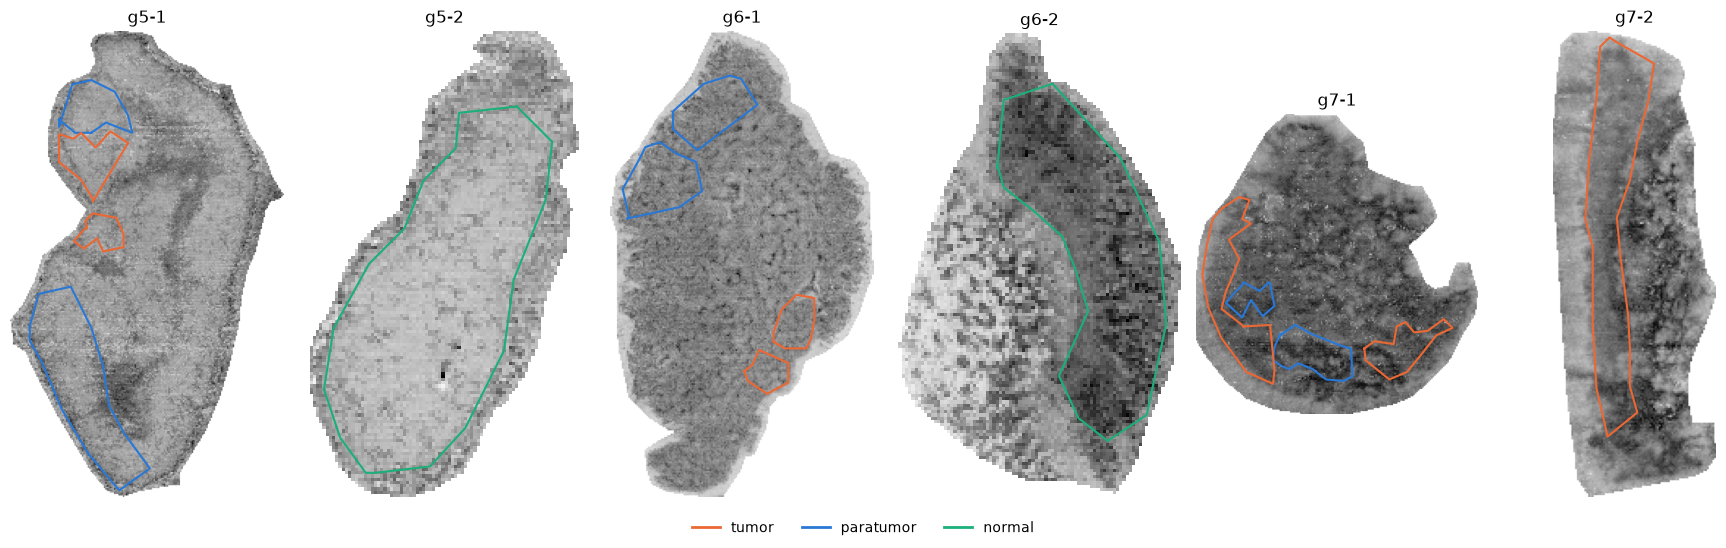

In [6]:
REGION_TYPES = {"T": "tumor", "PT": "paratumor", "N": "normal"}
COLORS = {"tumor": "#eb6834", "paratumor": "#2a78d6", "normal": "#1baf7a"}


def region_type(roi_name):
    """'PT_2' -> 'paratumor'"""
    return REGION_TYPES[roi_name.rsplit("_", 1)[0]]


fig, axes = plt.subplots(1, len(adatas), figsize=(3 * len(adatas), 5.5))
for ax, (sample, adata) in zip(axes, adatas.items()):
    ax.imshow(anndata_to_image_array(adata).sum(axis=0), cmap="Greys")
    for name, geometry in load_roi_geometries(samples.loc[sample, "roi_file"]).items():
        for polygon in getattr(geometry, "geoms", [geometry]):
            if polygon.geom_type == "Polygon":
                ax.plot(*polygon.exterior.xy, color=COLORS[region_type(name)], linewidth=1.5)
    ax.set_title(sample)
    ax.axis("off")
fig.legend(
    [Line2D([0], [0], color=c, linewidth=2) for c in COLORS.values()],
    COLORS.keys(),
    loc="lower center",
    ncol=3,
    frameon=False,
)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

## 4. Keep only the pixels inside an ROI

We subset every object to the labelled pixels and add the columns we need after merging:

- `sample` and `dataset_id`: which dataset a pixel comes from,
- `region_type`: `tumor`, `paratumor` or `normal`, from the ROI name,
- unique pixel names (prefixed with the sample), because every dataset numbers its pixels from 0.

In [7]:
ID_COLUMNS = ["formula", "adduct", "chemMod", "neutralLoss", "ion"]

roi_adatas = []
for sample, adata in adatas.items():
    roi = adata[adata.obs["ROI"].notna()].copy()
    roi.obs["ROI"] = roi.obs["ROI"].astype(str)
    roi.obs["region_type"] = roi.obs["ROI"].map(region_type)
    roi.obs["sample"] = sample
    roi.obs["dataset_id"] = samples.loc[sample, "dataset_id"]
    roi.obs_names = f"{sample}_" + roi.obs_names
    # The scores in .var (msm, fdr, ...) belong to one dataset, so keep only the ion identity.
    roi.var = roi.var[ID_COLUMNS]
    roi_adatas.append(roi)

pd.DataFrame({a.obs["sample"].iloc[0]: {"pixels in ROIs": a.n_obs, "ions": a.n_vars} for a in roi_adatas}).T

,pixels in ROIs,ions
g5-1,7648,555
g5-2,4705,365
g6-1,4059,1128
g6-2,2993,343
g7-1,5292,982
g7-2,4301,846


## 5. Merge into one AnnData

`anndata.concat` stacks the pixels of all datasets. Each dataset has a different set of annotated ions, so we use `join="inner"`: the merged object keeps only the ions annotated **in every dataset**. Every ion then has a measured value in every pixel. (An outer join would keep all ions but fill the gaps with zeros, which would mix "not detected" with "not annotated".)

In [8]:
merged = ad.concat(roi_adatas, join="inner", merge="same")
merged.strings_to_categoricals()

merged.uns["datasets"] = (
    samples.drop(columns="roi_file").assign(database=" ".join(DATABASE), fdr=FDR).reset_index()
)
print(f"{merged.n_obs} pixels x {merged.n_vars} ions kept")
print(f"ions per dataset before merging: { {a.obs['sample'].iloc[0]: a.n_vars for a in roi_adatas} }")
merged

28998 pixels x 125 ions kept
ions per dataset before merging: {'g5-1': 555, 'g5-2': 365, 'g6-1': 1128, 'g6-2': 343, 'g7-1': 982, 'g7-2': 846}


AnnData object with n_obs × n_vars = 28998 × 125
    obs: 'ion_image_pixel_x', 'ion_image_pixel_y', 'ion_image_shape_y', 'ion_image_shape_x', 'ROI', 'region_type', 'sample', 'dataset_id'
    var: 'formula', 'adduct', 'chemMod', 'neutralLoss', 'ion'
    uns: 'datasets'
    obsm: 'spatial'
    layers: None (.X)

In [9]:
pd.crosstab(merged.obs["sample"], merged.obs["ROI"])

ROI,N_1,PT_1,PT_2,T_1,T_2
sample,,,,,
g5-1,0,1202,4662,1205,579
g5-2,4705,0,0,0,0
g6-1,0,1383,1521,674,481
g6-2,2993,0,0,0,0
g7-1,0,1272,465,1071,2484
g7-2,0,0,0,4301,0


Notes on the merged object:

- `obs["ion_image_pixel_x"]` and `obs["ion_image_pixel_y"]` are pixel positions **within each dataset**, so they overlap between datasets. Select one `sample` before plotting positions.
- Intensities are in the original units of each dataset, which can differ between acquisitions. Compare regions **within** a sample, or pass `use_tic=True` to `metaspace_to_anndata` to normalize by total ion count before merging.
- Several HMDB annotations can share the same peak (isobaric ions). They then have identical ion images.
- The score columns (`msm`, `fdr`, ...) differ between datasets and are not kept. They remain in the per-dataset objects in `adatas`.

## 6. A first look at the merged data

The ions with the largest relative difference in mean intensity between tumor and normal pixels, shown as mean intensity per region type, scaled to each ion's maximum. Ions that share a peak have identical profiles, so each profile is shown once. This is a quick look at the labels, not a statistical test: normal pixels come from two samples and tumor pixels from others, so sample differences are mixed in.

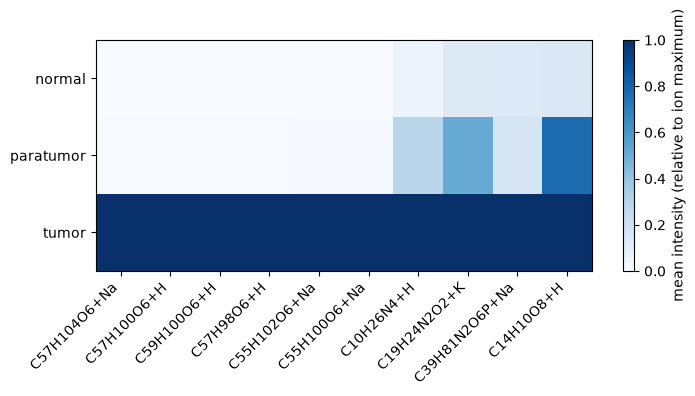

In [10]:
intensities = pd.DataFrame(merged.X, index=merged.obs_names, columns=merged.var_names)
means = intensities.groupby(merged.obs["region_type"].to_numpy(), observed=True).mean()
means = means.T.drop_duplicates().T  # ions sharing a peak have identical profiles
relative_difference = (means.loc["tumor"] - means.loc["normal"]) / (means.loc["tumor"] + means.loc["normal"])
top = relative_difference.abs().nlargest(10).index
scaled = means[top].div(means[top].max())

fig, ax = plt.subplots(figsize=(8, 3))
image = ax.imshow(scaled.loc[["normal", "paratumor", "tumor"]], cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(top)), top, rotation=45, ha="right")
ax.set_yticks(range(3), ["normal", "paratumor", "tumor"])
fig.colorbar(image, ax=ax, label="mean intensity (relative to ion maximum)")
plt.show()

## 7. Save the result

The merged object is the output of this notebook. Write it to an `.h5ad` file and read it back to check that it is complete. From here you can continue with scanpy, for example for PCA, clustering or differential analysis.

In [11]:
output = DATA_DIR / "cancer_rois_merged.h5ad"
merged.write_h5ad(output, compression="gzip")

reloaded = ad.read_h5ad(output)
print(reloaded.shape == merged.shape, f"{output.stat().st_size / 1e6:.1f} MB")
reloaded

True 5.8 MB


AnnData object with n_obs × n_vars = 28998 × 125
    obs: 'ion_image_pixel_x', 'ion_image_pixel_y', 'ion_image_shape_y', 'ion_image_shape_x', 'ROI', 'region_type', 'sample', 'dataset_id'
    var: 'formula', 'adduct', 'chemMod', 'neutralLoss', 'ion'
    uns: 'datasets'
    obsm: 'spatial'
    layers: None (.X)